![imagen](./img/python.jpg)

# Obtención de Datos Mediante APIs en Python

Una de las formas de obtención de datos online más comunes es a través de **APIs (Application Programming Interfaces)**. Las APIs son una forma eficiente de acceder a datos y servicios en línea. Aprenderemos a realizar solicitudes a través de Python utilizando la popular biblioteca `requests`.

**En este notebook aprenderás:**

1. Qué es una API y en qué se diferencia de descargar un fichero.
2. Cómo funciona una comunicación HTTP: petición, respuesta, métodos y códigos de estado.
3. Los distintos tipos de parámetros (ruta, consulta y cuerpo).
4. A usar `requests` y a interpretar el objeto `Response`.
5. A convertir respuestas JSON en `DataFrame`.
6. Buenas prácticas: errores, `timeout`, límites de peticiones, paginación y gestión de claves secretas.

## Introducción a las APIs

Una API (Application Programming Interface) es un conjunto de reglas y protocolos que permiten a diferentes aplicaciones interactuar entre sí. Las APIs permiten a las aplicaciones solicitar datos o realizar acciones en un servidor remoto de manera estructurada y estandarizada.

![imagen](./img/http.PNG)

### APIs REST

La mayoría de APIs web que usarás siguen el estilo **REST** (*Representational State Transfer*). Sus ideas principales:

* **Todo es un recurso**: usuarios, productos, chistes, cafeterías... Cada recurso tiene una dirección (URL).  

* **URL base + endpoint**: la API tiene una dirección común (URL base) y, a partir de ella, cada **endpoint** da acceso a un recurso concreto:

  | URL base | Endpoint | URL completa |
  |---|---|---|
  | `https://api.chucknorris.io` | `/jokes/random` | `https://api.chucknorris.io/jokes/random` |
  | `https://api.chucknorris.io` | `/jokes/categories` | `https://api.chucknorris.io/jokes/categories` |  
  
  </br>

* **Sin estado (*stateless*)**: cada petición es independiente. El servidor no "recuerda" quién eres entre una petición y otra, así que cada petición debe llevar toda la información necesaria (parámetros, credenciales...).  

* **Las URL representan nombres (recursos), no acciones**: la acción la indica el método HTTP (GET, POST...).
* **Las respuestas suelen venir en JSON**, un formato que en Python se traduce directamente a diccionarios y listas.

### ¿Descargar un fichero o consumir una API?

En este notebook veremos dos formas de obtener datos de internet que conviene no confundir:

| | Descarga de fichero | API |
|---|---|---|
| Qué hay detrás de la URL | Un fichero ya generado (CSV, ZIP, imagen...) | Un programa que genera la respuesta |
| ¿Acepta parámetros? | No, siempre devuelve lo mismo | Sí, la respuesta depende de lo que pidas |
| Formato típico | CSV, XLSX, ZIP, JPG | JSON (a veces XML) |
| Ejemplos del notebook | Imagen, inflación, Bicimad | Chuck Norris, OpenStreetMap |

Ambas usan HTTP y la librería `requests`, por eso empezamos por ahí.

## Protocolo HTTP

El Protocolo de Transferencia de Hipertexto (HTTP) es el protocolo subyacente utilizado en la World Wide Web. Se utiliza para solicitar y transmitir datos en la web. Funciona siempre igual: un **cliente** (tu navegador o tu código Python) envía una **petición** y un **servidor** devuelve una **respuesta**.

![imagen](./img/peticion_respuesta.PNG)

Aquí tienes un ejemplo de arquitectura:

![imagen](./img/arquitectura_servidor.PNG)

**Partes de una petición (request):**

* **Método**: qué queremos hacer (GET, POST...).
* **URL**: a qué recurso nos dirigimos.
* **Headers (cabeceras)**: metadatos de la petición, p. ej. qué formato aceptamos, quién hace la petición (`User-Agent`) o nuestras credenciales (`Authorization`).
* **Body (cuerpo)**: datos que enviamos al servidor (solo en algunos métodos, como POST o PUT).

**Partes de una respuesta (response):**

* **Código de estado**: un número que indica si ha ido bien o mal (200, 404...).
* **Headers**: metadatos, p. ej. `Content-Type` indica el formato del contenido (`application/json`, `image/jpeg`, `application/zip`...).
* **Body**: el contenido en sí (el JSON, la imagen, el CSV...).

**Métodos HTTP más comunes:**

| Método | Para qué sirve | Ejemplo |
|---|---|---|
| **GET** | Recuperar datos | Obtener un chiste |
| **POST** | Enviar datos al servidor (crear un recurso o mandar una consulta) | Valorar una película, enviar una consulta |
| **PUT** | Reemplazar un recurso completo | Sustituir el perfil de un usuario |
| **PATCH** | Modificar parte de un recurso | Cambiar solo el email |
| **DELETE** | Eliminar un recurso | Borrar una valoración |

Como analistas de datos usaremos sobre todo **GET** (y alguna vez POST para enviar consultas largas).

### Parámetros de una petición

Una misma API puede devolvernos cosas distintas según los **parámetros** que le pasemos. Hay tres sitios donde pueden ir:

![imagen](./img/parametros.PNG)

1. **Parámetros de ruta (*path*)**: forman parte de la propia URL e identifican el recurso.
   `https://api.github.com/users/`**`octocat`** → el usuario es parte de la ruta.
2. **Parámetros de consulta (*query*)**: van al final de la URL, tras un `?`, con formato `clave=valor` y separados por `&`.
   `https://api.chucknorris.io/jokes/random`**`?category=science`**
3. **Parámetros en el cuerpo (*body*)**: viajan dentro de la petición, no en la URL. Se usan con POST/PUT/PATCH, por ejemplo para enviar un JSON o una consulta muy larga.

¿Qué parámetros acepta cada endpoint y dónde van? Eso solo lo dice **la documentación de la API**.

### Códigos de estado

Cada respuesta trae un código de estado. Lo importante es saber leer la **familia** (el primer dígito):

![imagen](./img/status_codes.PNG)

| Familia | Significado | Códigos que verás a menudo |
|---|---|---|
| **1xx** | Informativo | (raros en la práctica) |
| **2xx** | Éxito | **200** OK, **201** Creado |
| **3xx** | Redirección | **301** Movido permanentemente |
| **4xx** | Error del **cliente** (nuestro) | **400** petición mal formada, **401** no autenticado (falta o falla la API key), **403** prohibido (sin permisos), **404** no encontrado, **429** demasiadas peticiones |
| **5xx** | Error del **servidor** | **500** error interno, **503** servicio no disponible |

Regla práctica: si es un **4xx**, revisa tu petición (URL, parámetros, credenciales); si es un **5xx**, el problema no es tuyo: espera y reintenta.

### Cómo leer la documentación de una API

Antes de usar cualquier API hay que leer su documentación. Casi todas responden a las mismas preguntas:

* **URL base** y lista de **endpoints**.
* **Método** de cada endpoint (GET, POST...).
* **Parámetros**: cuáles son obligatorios, cuáles opcionales y si van en la ruta, en la consulta o en el cuerpo.
* **Autenticación**: si hace falta registrarse y obtener una API key o token.
* **Formato de la respuesta**: ejemplo del JSON devuelto y significado de cada campo.
* **Límites de uso** (*rate limits*) y condiciones/licencia de los datos.

Muchas APIs ofrecen documentación interactiva (Swagger / OpenAPI, "API explorer") donde puedes probar las peticiones desde el navegador antes de escribir código.

![imagen](./img/documentacion_api.PNG)

## Biblioteca ``requests``

La biblioteca requests es una de las más populares para realizar solicitudes HTTP en Python. Permite enviar solicitudes y procesar respuestas de una manera sencilla y eficiente.

In [ ]:
q# %pip install requests

In [2]:
# Importamos librerias
import os
import time
import requests
import zipfile
import pandas as pd

## Primera petición

Empezamos con lo más sencillo: descargar una imagen. No es una API (es un fichero), pero nos sirve para conocer `requests.get()` y el objeto que devuelve.

In [3]:
url = "https://pbs.twimg.com/profile_images/616689518968762368/rkhjKqNb.jpg"
image = requests.get(url)

In [4]:
image


<Response [200]>

`requests.get()` devuelve un objeto **`Response`**. Sus atributos y métodos más útiles:

| Atributo / método | Qué contiene |
|---|---|
| `.status_code` | Código de estado (200, 404...) |
| `.ok` | `True` si el código es menor que 400 |
| `.headers` | Diccionario con las cabeceras de la respuesta |
| `.url` | URL final a la que se hizo la petición (útil para ver cómo quedaron los parámetros) |
| `.content` | Cuerpo en **bytes** → para contenido binario (imágenes, ZIP, PDF) |
| `.text` | Cuerpo como **texto** (str) → para HTML, CSV, JSON en crudo |
| `.json()` | Convierte un cuerpo JSON en **diccionario/lista** de Python |
| `.raise_for_status()` | Lanza una excepción si el código es 4xx o 5xx |

In [5]:
print(image.status_code)
print(image.ok)
print(image.headers['Content-Type'])
print(image.url)

200
True
image/jpeg
https://pbs.twimg.com/profile_images/616689518968762368/rkhjKqNb.jpg


Como es una imagen (`image/jpeg`), su contenido es binario y lo leemos con `.content`:

In [6]:
image.content

b'\xff\xd8\xff\xe0\x00\x10JFIF\x00\x01\x01\x00\x00\x01\x00\x01\x00\x00\xff\xe2\x02\xa0ICC_PROFILE\x00\x01\x01\x00\x00\x02\x90lcms\x040\x00\x00mntrRGB XYZ \x07\xdf\x00\x07\x00\x02\x00\x13\x00\x1a\x005acspAPPL\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\xf6\xd6\x00\x01\x00\x00\x00\x00\xd3-lcms\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x0bdesc\x00\x00\x01\x08\x00\x00\x008cprt\x00\x00\x01@\x00\x00\x00Nwtpt\x00\x00\x01\x90\x00\x00\x00\x14chad\x00\x00\x01\xa4\x00\x00\x00,rXYZ\x00\x00\x01\xd0\x00\x00\x00\x14bXYZ\x00\x00\x01\xe4\x00\x00\x00\x14gXYZ\x00\x00\x01\xf8\x00\x00\x00\x14rTRC\x00\x00\x02\x0c\x00\x00\x00 gTRC\x00\x00\x02,\x00\x00\x00 bTRC\x00\x00\x02L\x00\x00\x00 chrm\x00\x00\x02l\x00\x00\x00$mluc\x00\x00\x00\x00\x00\x00\x00\x01\x00\x00\x00\x0cenUS\x00\x00\x00\x1c\x00\x00\x00\x1c\x00s

In [7]:
# %pip install pillow

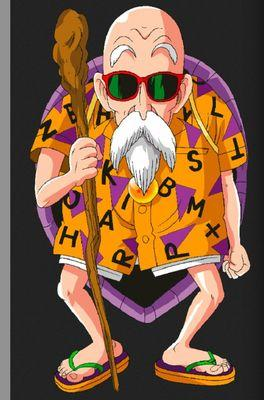

In [8]:
from PIL import Image
from io import BytesIO

i = Image.open(BytesIO(image.content))
i


Para guardar contenido binario abrimos el fichero en modo **`'wb'`** (*write binary*). Para texto usaríamos `'w'`. Nos aseguramos antes de que la carpeta `data` existe:

In [9]:
os.makedirs("data", exist_ok=True)

with open("data/maestro_mutenrroy.jpg", 'wb') as f:
    f.write(image.content)

### Mediante pandas

Si la URL apunta directamente a un fichero CSV (o Excel, JSON...), `pandas` puede leerlo sin pasar por `requests`: hace la petición GET por nosotros. De nuevo, es una descarga de fichero, no una API.

In [10]:
df_inflation = pd.read_csv('https://datahub.io/core/inflation/r/inflation-gdp.csv')
df_inflation.head()

,Country,Country Code,Year,Inflation
0,Aruba,ABW,1985,4.032258
1,Aruba,ABW,1986,1.073966
2,Aruba,ABW,1987,3.643045
3,Aruba,ABW,1988,3.121868
4,Aruba,ABW,1989,3.991628


In [11]:
df_inflation[df_inflation['Country'] == "Spain"]

,Country,Country Code,Year,Inflation
2904,Spain,ESP,1960,1.177771
2905,Spain,ESP,1961,0.809253
2906,Spain,ESP,1962,5.706477
2907,Spain,ESP,1963,8.743698
2908,Spain,ESP,1964,6.979247
...,...,...,...,...
2964,Spain,ESP,2020,-0.322753
2965,Spain,ESP,2021,3.093135
2966,Spain,ESP,2022,8.390576
2967,Spain,ESP,2023,3.532361


## Bajar datos de Bicimad

La EMT de Madrid publica los datos históricos de viajes de BiciMAD en su [portal de datos abiertos](https://opendata.emtmadrid.es/). Descargamos un ZIP:

1. Hacemos la petición y comprobamos con el header `Content-Type` que es un ZIP.
2. Lo guardamos en modo binario (`'wb'`).
3. Lo descomprimimos con `zipfile`.

> ⚠️ El enlace es una URL corta del portal; si deja de funcionar, búscalo de nuevo en el portal de datos abiertos de la EMT.

In [12]:
url = 'https://media.emtmadrid.es/-9Nii5DXo4x'

r = requests.get(url)

In [13]:
r

<Response [200]>

In [14]:
r.headers.get('Content-Type')

'application/zip'

In [15]:
# Guardamos el zip
filename = 'data/bicis.zip'
with open(filename, 'wb') as f:
    f.write(r.content)

In [16]:
# Extraemos lo que hay dentro
filename = 'data/bicis.zip'
with zipfile.ZipFile(filename) as zip_ref:
    zip_ref.extractall("data")

In [17]:
# Extraemos el zip dentro del zip...
filename = 'data/bicimad_2023/trips_23_01_January-csv.zip'
with zipfile.ZipFile(filename) as zip_ref:
    zip_ref.extractall("data/bicimad_2023")

In [18]:
# Leemos los datos
datos_bicis = pd.read_csv('data/bicimad_2023/trips_23_01_January.csv', sep=";", nrows=10000)

In [19]:
# Vemos qué pinta tienen
datos_bicis.head()

,fecha,idBike,fleet,trip_minutes,geolocation_unlock,address_unlock,unlock_date,locktype,unlocktype,geolocation_lock,address_lock,lock_date,station_unlock,dock_unlock,unlock_station_name,station_lock,dock_lock,lock_station_name
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-01-01,3728.0,1.0,35.10,"{'type': 'Point', 'coordinates': [-3.6954403, ...",'Plaza de Alonso Martínez nº 5',2023-01-01T00:01:08,STATION,STATION,"{'type': 'Point', 'coordinates': [-3.6954403, ...",'Plaza de Alonso Martínez nº 5',2023-01-01T00:36:14,9.0,9.0,8 - Alonso Martínez,9.0,10.0,8 - Alonso Martínez
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2023-01-01,4465.0,1.0,8.33,"{'type': 'Point', 'coordinates': [-3.7081246, ...",'Plaza de Santo Domingo nº 1',2023-01-01T00:01:45,STATION,STATION,"{'type': 'Point', 'coordinates': [-3.71019, 40...",'Calle Galileo nº 63',2023-01-01T00:10:05,26.0,20.0,23 - Santo Domingo,253.0,9.0,245 - Galileo
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [20]:
datos_bicis.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   fecha                5000 non-null   str    
 1   idBike               5000 non-null   float64
 2   fleet                5000 non-null   float64
 3   trip_minutes         5000 non-null   float64
 4   geolocation_unlock   5000 non-null   str    
 5   address_unlock       5000 non-null   str    
 6   unlock_date          5000 non-null   str    
 7   locktype             5000 non-null   str    
 8   unlocktype           5000 non-null   str    
 9   geolocation_lock     5000 non-null   str    
 10  address_lock         5000 non-null   str    
 11  lock_date            5000 non-null   str    
 12  station_unlock       4985 non-null   float64
 13  dock_unlock          4985 non-null   float64
 14  unlock_station_name  4985 non-null   str    
 15  station_lock         4987 non-null   float64
 16

In [21]:
datos_bicis['address_unlock'].value_counts(dropna=False)

address_unlock
NaN                                                                 5000
'Calle Princesa nº 5'                                                 76
'Calle Segovia nº 45'                                                 69
'Glorieta Marqués de Vadillo nº 9'                                    67
'Plaza de San Ildefonso'                                              67
                                                                    ... 
'Avenida de los Toreros nº 49'                                         1
'28007,ES,Madrid,Madrid,Plaza del Embarcadero de atocha ,Madrid'       1
'28019,ES,Madrid,Madrid,Calle de Alejandro sánchez 63,Madrid'          1
'28050,ES,Madrid,Madrid,Calle de Ana de austria 4,Madrid'              1
'28046,ES,Madrid,Madrid,Calle de Mauricio legendre 38D,Madrid'         1
Name: count, Length: 261, dtype: int64

# Acceso a archivos de la pagina del INE
Uno de los mayores catálogos de información pública descargable en España

<table align="left">
 <tr><td width="80"><img src="./img/ejercicio.png" style="width:auto;height:auto"></td>
     <td style="text-align:left">
         <h3>Ejercicio ine.es</h3>

Descarga con pandas un dataset de la página https://www.ine.es/dyngs/INEbase/listaoperaciones.htm acerca del empleo y guárdalo en un csv en la carpeta data. Puedes utilizar pandas.

**Extra**: el INE también ofrece una **API JSON** (servicio Tempus). Consulta su [manual](https://www.ine.es/dyngs/DataLab/manual.html?cid=45) e intenta obtener los mismos datos haciendo una petición con `requests`.

 </td></tr>
</table>

## Api chucknorris

[Enlace API](https://api.chucknorris.io/)

Nuestra primera API de verdad: gratuita, sin registro y con respuestas en JSON. En la documentación vemos que tiene, entre otros, estos endpoints (todos GET):

| Endpoint | Qué devuelve | Parámetros |
|---|---|---|
| `/jokes/random` | Un chiste aleatorio | `category` (query, opcional) |
| `/jokes/categories` | Lista de categorías | — |
| `/jokes/search` | Chistes que contienen un texto | `query` (query, obligatorio) |  

</br>

> Nota: la API incluye una categoría `explicit` con contenido no apto. Tenlo en cuenta al usar chistes aleatorios.

In [22]:
url = "https://api.chucknorris.io/jokes/random"  # Reemplaza con la URL de la API que deseas acceder.

response = requests.get(url)

if response.status_code == 200:  # Código 200 indica una respuesta exitosa.
    data = response.json()  # Analizar la respuesta JSON.
    print(data["value"])
else:
    print("Error en la solicitud: ", response.status_code)

Chuck Norris recently attended a Black Panther and KKK rally at the South Carolina state house. Authorities found no survivors.


### Manejo de errores

En el mundo real las peticiones fallan: no hay conexión, el servidor tarda demasiado, la URL está mal... Una función para llamar a una API debería:

* Usar siempre un **`timeout`** (segundos máximos de espera). Sin él, si el servidor no responde, tu código se queda colgado indefinidamente.  

* Comprobar el código de estado; `raise_for_status()` lanza un `HTTPError` si es 4xx/5xx.
* Capturar las excepciones de `requests` (todas heredan de `requests.exceptions.RequestException`) y **devolver algo explícito** en caso de error, en lugar de fallar en silencio.
* Pasar los parámetros de consulta con el argumento **`params`** (un diccionario) en lugar de pegarlos a mano en la URL: `requests` se encarga de añadir `?` y `&` y de **codificar** los caracteres especiales (los espacios pasan a `%20`, las tildes se codifican, etc.).

In [23]:
def get_joke(url, params=None):
    try:
        response = requests.get(url, params=params, timeout=10)
        response.raise_for_status()  # Lanza HTTPError si el código es 4xx o 5xx
        return response.json()       # Analizar la respuesta JSON
    except requests.exceptions.Timeout:
        print("El servidor ha tardado demasiado en responder")
    except requests.exceptions.HTTPError as e:
        print("Error HTTP:", e)
    except requests.exceptions.RequestException as e:
        print("Error en la solicitud:", e)
    return None

In [24]:
url = "https://api.chucknorris.io/jokes/categories"
get_joke(url)

['animal',
 'career',
 'celebrity',
 'dev',
 'explicit',
 'fashion',
 'food',
 'history',
 'money',
 'movie',
 'music',
 'political',
 'religion',
 'science',
 'sport',
 'travel']

Pasamos la categoría como parámetro de consulta con `params`. Fíjate en cómo `requests` construye la URL final:

In [25]:
categoria = "science"
url = "https://api.chucknorris.io/jokes/random"
get_joke(url, params={"category": categoria})

{'categories': ['science'],
 'created_at': '2020-01-05 13:42:19.576875',
 'icon_url': 'https://api.chucknorris.io/img/avatar/chuck-norris.png',
 'id': 'h2le0vpkstise9oetsodmw',
 'updated_at': '2020-01-05 13:42:19.576875',
 'url': 'https://api.chucknorris.io/jokes/h2le0vpkstise9oetsodmw',
 'value': "Newton's Third Law is wrong: Although it states that for each action, there is an equal and opposite reaction, there is no force equal in reaction to a Chuck Norris roundhouse kick."}

In [26]:
# ¿Qué URL ha construido requests?
requests.get(url, params={"category": categoria}, timeout=10).url

'https://api.chucknorris.io/jokes/random?category=science'

In [27]:
# Si algo falla, la función nos avisa y devuelve None
get_joke("https://api.chucknorris.io/jokes/no_existe")

Error HTTP: 404 Client Error: Not Found for url: https://api.chucknorris.io/jokes/no_existe


El endpoint de búsqueda devuelve un diccionario con el total de resultados y una lista de chistes. Exploramos su estructura antes de usarlo:

In [28]:
url = "https://api.chucknorris.io/jokes/search"
resultado = get_joke(url, params={"query": "computer"})

print(resultado.keys())
print("Total:", resultado["total"])
print("Campos de cada chiste:", resultado["result"][0].keys())

dict_keys(['total', 'result'])
Total: 26
Campos de cada chiste: dict_keys(['categories', 'created_at', 'icon_url', 'id', 'updated_at', 'url', 'value'])


# Paginación

Cuando un endpoint tiene muchos resultados, la API no los devuelve todos de golpe: los divide en **páginas**. Es fundamental en ciencia de datos, porque normalmente queremos *todos* los registros, no solo los primeros.

Las formas más habituales de paginar (la documentación indica cuál usa cada API):

* **`page` / `per_page`**: `?page=2&per_page=100`  

* **`offset` / `limit`**: `?offset=200&limit=100` (sáltate 200, dame 100)
* **Enlace `next`**: la respuesta incluye la URL de la siguiente página; cuando es `null`, hemos terminado.

Lo vemos con la [PokéAPI](https://pokeapi.co/), que usa `offset`/`limit` y devuelve un enlace `next`:

In [29]:
url = "https://pokeapi.co/api/v2/pokemon"
params = {"limit": 200}

pokemons = []
while url:
    response = requests.get(url, params=params, timeout=10)
    response.raise_for_status()
    data = response.json()

    pokemons.extend(data["results"])
    url = data["next"]   # None en la última página -> sale del bucle
    params = None        # La URL de 'next' ya incluye los parámetros
    time.sleep(0.5)      # Pausa entre peticiones para no saturar la API

print(len(pokemons), "pokémon descargados")
df_poke = pd.DataFrame(pokemons)
df_poke.head()

1351 pokémon descargados


,name,url
0,bulbasaur,https://pokeapi.co/api/v2/pokemon/1/
1,ivysaur,https://pokeapi.co/api/v2/pokemon/2/
2,venusaur,https://pokeapi.co/api/v2/pokemon/3/
3,charmander,https://pokeapi.co/api/v2/pokemon/4/
4,charmeleon,https://pokeapi.co/api/v2/pokemon/5/


# Buenas prácticas y uso responsable de APIs

* **`timeout`** en todas las peticiones, como hemos visto.  

* **Límites de uso (*rate limits*)**: casi todas las APIs limitan cuántas peticiones puedes hacer (p. ej. 5 por segundo o 5.000 al día). Si te pasas, responden **429 Too Many Requests** o te bloquean. Usa `time.sleep()` entre peticiones en los bucles y, si recibes un 429, espera antes de reintentar (a veces el header `Retry-After` indica cuántos segundos).
* **`User-Agent`**: es un header que identifica quién hace la petición. Algunas APIs públicas (como Overpass, que usaremos ahora) piden que pongas el nombre de tu aplicación y un contacto, y pueden rechazar peticiones anónimas.
* **No repitas peticiones innecesarias**: guarda los datos descargados en disco (JSON/CSV) y trabaja sobre la copia local.
* **Condiciones de uso y licencia**: los datos de una API tienen dueño. Revisa qué puedes hacer con ellos y si debes citar la fuente.
* **SDKs**: algunos servicios ofrecen librerías de Python que encapsulan las llamadas a su API (por ejemplo, `wikipedia` o `spotipy`). Por debajo hacen lo mismo que nosotros con `requests`, pero con una interfaz más cómoda.

# Autenticación: API keys y tokens

Las APIs de este notebook son abiertas, pero la mayoría de APIs reales (TMDB, OpenWeatherMap, Spotify, Ticketmaster...) exigen registrarse para identificar quién hace cada petición. Tras el registro te dan una credencial, que suele ir de una de estas formas:

* **API key como parámetro de consulta**: `https://api.ejemplo.com/datos?api_key=TU_CLAVE`
* **Token en un header**, normalmente `Authorization: Bearer TU_TOKEN`

Si la credencial falta o es incorrecta, la API responde **401** (o **403** si no tienes permiso para ese recurso).

### **Muy Importante: Nunca escribas tus claves en el código**

Una API key es como una contraseña: quien la tenga puede usar la API en tu nombre (y gastar tu cuota o tu dinero). Si la escribes en un notebook y lo subes a GitHub, queda publicada (incluso en los *outputs* de las celdas).

Para este ejemplo usaremos la web de The Movie DataBase. La práctica habitual suele ser algo así:

1. Date de alta en la página y consigue tu API key: https://www.themoviedb.org/

2. Si tienes dudas, visita la página de ayuda: https://developer.themoviedb.org/reference/authentication

3. Guarda las claves en un fichero **`.env`** en la raíz del proyecto:
   ```
   TMDB_TOKEN=eyJhbGciOi...
   ```
4. Añade `.env` al **`.gitignore`** para que git nunca lo suba.
5. Sube un **`.env.example`** con los nombres de las variables pero sin valores, para que otros sepan qué claves necesitan.
6. Lee las claves desde Python con la librería `python-dotenv`:

In [30]:
%pip install python-dotenv


[notice] A new release of pip is available: 25.0.1 -> 26.2.1
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [39]:
from dotenv import load_dotenv

load_dotenv()  # Carga las variables del fichero .env como variables de entorno

token = os.getenv("TMDB_TOKEN")  # None si la variable no existe

# Ejemplo de uso con un token en el header (no se ejecuta si no tienes token)
if token:
    response = requests.get(
        "https://api.themoviedb.org/3/search/movie",
        params={"query": "Spirited Away"},
        headers={"Authorization": f"Bearer {token}"},
        timeout=10,
    )
    print(response.status_code)
else:
    print("No hay TMDB_TOKEN en el fichero .env")

200


# Datos geográficos: OpenStreetMap

[OpenStreetMap](https://www.openstreetmap.org/) es un mapa colaborativo y abierto. Para consultar sus datos usamos la **Overpass API**, que recibe consultas escritas en su propio lenguaje, *Overpass QL*:

```
[out:json][timeout:25];                                   -> formato de salida JSON y tiempo máximo
node["amenity"="cafe"](39.4674,-0.3879,39.4818,-0.3669);  -> puntos etiquetados como cafetería dentro del rectángulo
out;                                                      -> devuelve los resultados
```

* `amenity` es la etiqueta de OSM para servicios (`cafe`, `restaurant`, `pharmacy`...); [lista completa](https://wiki.openstreetmap.org/wiki/Key:amenity).  

* El rectángulo (*bounding box*) se escribe como **(sur, oeste, norte, este)**, es decir, (lat. mínima, lon. mínima, lat. máxima, lon. máxima). Puedes sacar las coordenadas de Google Maps u OpenStreetMap.

**¿Por qué POST si solo queremos leer?** Porque la consulta puede ser larga y es más cómodo enviarla en el **cuerpo** de la petición que en la URL. Overpass acepta ambas opciones. En `requests` el cuerpo se envía así:

| Argumento | Dónde van los datos | Cuándo usarlo |
|---|---|---|
| `params={...}` | En la URL (query) | GET con parámetros de consulta |
| `data={...}` | En el cuerpo, como formulario | Lo que pide Overpass |
| `json={...}` | En el cuerpo, como JSON | APIs que esperan un JSON (lo más habitual en POST) |

Además, enviamos un `User-Agent` identificativo y un `timeout`, como pide la política de uso de Overpass.

In [32]:
# Amenities
# https://wiki.openstreetmap.org/wiki/Key:amenity

overpass_url = "https://overpass-api.de/api/interpreter"

# bbox: (sur, oeste, norte, este)
overpass_query = """
[out:json][timeout:25];
node["amenity"="cafe"](40.43000, -3.69201 ,40.44447, -3.67101);
out;
"""

response = requests.post(
    overpass_url,
    data={'data': overpass_query},
    headers={
        'User-Agent': 'AnalisisCafesMadrid/1.0 (tu_email@ejemplo.com)',
        'Accept': '*/*'
    },
    timeout=60,
)

print(response.status_code)
if response.status_code != 200:
    print(response.text[:1000])
else:
    data = response.json()
    print(len(data['elements']), 'cafeterías encontradas')

502
# 502 Gateway Timeout

This Overpass API server is currently at capacity. All query workers are busy
and the request queue is full.

## What to do

Retry your request using exponential backoff: wait a short interval, then retry.
If the request fails again, double the wait time and retry again.

## For heavy or automated use

This public endpoint is intended for browser-based and human-operated tools.
For automated or high-volume use, run a local Overpass API instance:

https://github.com/b1tw153/Overpass-API/blob/main/README.md



In [33]:
data

{'count': 1351,
 'next': None,
 'previous': 'https://pokeapi.co/api/v2/pokemon?offset=1049&limit=151',
 'results': [{'name': 'darumaka-galar',
   'url': 'https://pokeapi.co/api/v2/pokemon/10176/'},
  {'name': 'darmanitan-galar-standard',
   'url': 'https://pokeapi.co/api/v2/pokemon/10177/'},
  {'name': 'darmanitan-galar-zen',
   'url': 'https://pokeapi.co/api/v2/pokemon/10178/'},
  {'name': 'yamask-galar', 'url': 'https://pokeapi.co/api/v2/pokemon/10179/'},
  {'name': 'stunfisk-galar',
   'url': 'https://pokeapi.co/api/v2/pokemon/10180/'},
  {'name': 'zygarde-10', 'url': 'https://pokeapi.co/api/v2/pokemon/10181/'},
  {'name': 'cramorant-gulping',
   'url': 'https://pokeapi.co/api/v2/pokemon/10182/'},
  {'name': 'cramorant-gorging',
   'url': 'https://pokeapi.co/api/v2/pokemon/10183/'},
  {'name': 'toxtricity-low-key',
   'url': 'https://pokeapi.co/api/v2/pokemon/10184/'},
  {'name': 'eiscue-noice', 'url': 'https://pokeapi.co/api/v2/pokemon/10185/'},
  {'name': 'indeedee-female',
   'ur

In [34]:
data.keys()

dict_keys(['count', 'next', 'previous', 'results'])

In [37]:
data['count']

1351

Podemos acceder a las claves de un diccionario con `[]` o con `.get()`. La diferencia: si la clave no existe, `[]` lanza un `KeyError` y `.get()` devuelve `None` (o el valor por defecto que le indiquemos, p. ej. `data.get("clave", [])`). En respuestas de APIs, donde no todos los registros tienen los mismos campos, `.get()` es más seguro.

In [ ]:
data.get('osm3s')

In [ ]:
data['osm3s']['copyright']

Los datos de OpenStreetMap se publican bajo licencia **ODbL**: puedes usarlos libremente, también con fines comerciales, siempre que **cites la fuente** ("© OpenStreetMap contributors") y compartas con la misma licencia las bases de datos derivadas.

In [ ]:
data.get("elements")

In [ ]:
data.get("elements")[60]['tags']

In [ ]:
for element in data['elements']:
    print(element)

In [ ]:
tag_set = set([])

for element in data['elements']:
    print(element['tags'])
    for tag in element['tags']:
        tag_set.add(tag)
        
tag_set	

In [ ]:
len(tag_set)

In [ ]:
df = pd.DataFrame(data.get("elements", []))
df

In [ ]:
df["tags"]

### `pd.json_normalize`

Al crear el `DataFrame` directamente, la columna `tags` contiene diccionarios: no podemos filtrar ni agrupar por sus campos. `pd.json_normalize` **aplana** las estructuras anidadas: cada clave interna se convierte en una columna con el prefijo del campo padre (`tags.name`, `tags.cuisine`...). Si un registro no tiene una clave, queda `NaN`.

Parámetros útiles:

* `sep`: separador del prefijo (por defecto `.`).
* `record_path`: si los registros están en una lista dentro de cada elemento, indica la ruta hasta ella.
* `meta`: campos del nivel superior que queremos conservar junto a cada registro de `record_path`.

In [ ]:
df = pd.json_normalize(data.get("elements", []))
df

In [ ]:
[col.replace('tags.', '') for col in df.columns]

In [ ]:
df.columns = [col.replace('tags.', '') for col in df.columns]

Muchas columnas apenas tienen datos. Nos quedamos con las que tienen más de un 10 % de valores no nulos:

In [ ]:
df_cafes = df[df.columns[df.notna().mean() * 100 > 10]]
df_cafes

Por último, guardamos los datos en disco para no tener que repetir la petición:

In [ ]:
df_cafes.to_csv("data/cafes_madrid.csv", index=False)

# Resumen

El flujo habitual para obtener datos de una API:

1. **Leer la documentación**: URL base, endpoint, método, parámetros, autenticación y límites.  

2. **Hacer la petición** con `requests`, con `params`, `headers` y `timeout`, y las claves leídas desde `.env`.
3. **Comprobar la respuesta**: código de estado y manejo de errores.
4. **Convertir el JSON** con `.json()` y explorarlo (`.keys()`, `.get()`).
5. **Recorrer todas las páginas** si hay paginación, respetando los límites de uso.
6. **Pasarlo a `DataFrame`** (`pd.DataFrame`, `pd.json_normalize`) y limpiarlo.
7. **Guardarlo** en disco (CSV, JSON) para no repetir peticiones.

# Para seguir practicando  

El repositorio [**public-apis**](https://github.com/public-apis/public-apis) recopila cientos de APIs gratuitas clasificadas por temas e indica si requieren autenticación.

Y también te dejamos a continuación una lista de APIs populares junto con sus URL base:

1. **OpenWeatherMap (Datos Meteorológicos)**
   - URL Base: `http://api.openweathermap.org/data/2.5/`
   - [Sitio Web](https://openweathermap.org/api)

2. **GitHub API (Interacción con Repositorios y Usuarios de GitHub)**
   - URL Base: `https://api.github.com/`
   - [Sitio Web](https://docs.github.com/en/rest)

3. **Spotify Web API (Datos de Música y Playlists)**
   - URL Base: `https://api.spotify.com/v1/`
   - [Sitio Web](https://developer.spotify.com/documentation/web-api/)

4. **X/Twitter API (Acceso a Datos de X/Twitter)**
   - URL Base: `https://api.x.com/`
   - [Sitio Web](https://docs.x.com/overview)

5. **Google Maps API (Servicios de Mapas y Localización)**
   - URL Base: Varía según el servicio (por ejemplo, Maps, Routes, Places)
   - [Sitio Web](https://developers.google.com/maps)

6. **Unsplash API (Fotos de Alta Resolución Gratuitas)**
   - URL Base: `https://api.unsplash.com/`
   - [Sitio Web](https://unsplash.com/developers)

7. **PokéAPI (Datos sobre Pokémon)**
   - URL Base: `https://pokeapi.co/api/v2/`
   - [Sitio Web](https://pokeapi.co/)

8. **NASA API (Imágenes y Datos de la NASA)**
    - URL Base: `https://api.nasa.gov/`
    - [Sitio Web](https://api.nasa.gov/)

9. **INE API (Instituto Nacional de Estadística de España)**  
	- [Sitio Web](https://www.ine.es/dyngs/DataLab/manual.html?cid=45)

10. **Idealista**  
    - [Sitio Web](https://developers.idealista.com/access-request)

11. **Tripadvisor**  
    - [Sitio Web](https://www.tripadvisor.com/developers)


